In [1]:
import sys
import tensorflow as tf

print("Python path:", sys.executable)
print("TensorFlow version:", tf.__version__)

Python path: c:\venvs\fashion-ml\Scripts\python.exe
TensorFlow version: 2.21.0



# Comparing Classical Machine Learning and Deep Learning for Fashion Image Classification

## 1. Introduction

This project compares two approaches to classifying clothing images using the Fashion-MNIST dataset.

The models are:
- Logistic Regression (Classical Machine Learning)
- Convolutional Neural Network (Deep Learning)

The aim is to compare model performance, understand how the models make predictions, and consider their limitations, ethical implications and possible use in an online retail system.


In [12]:

# Load Fashion-MNIST dataset

from tensorflow.keras.datasets import fashion_mnist

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Training labels: (60000,)
Testing labels: (10000,)


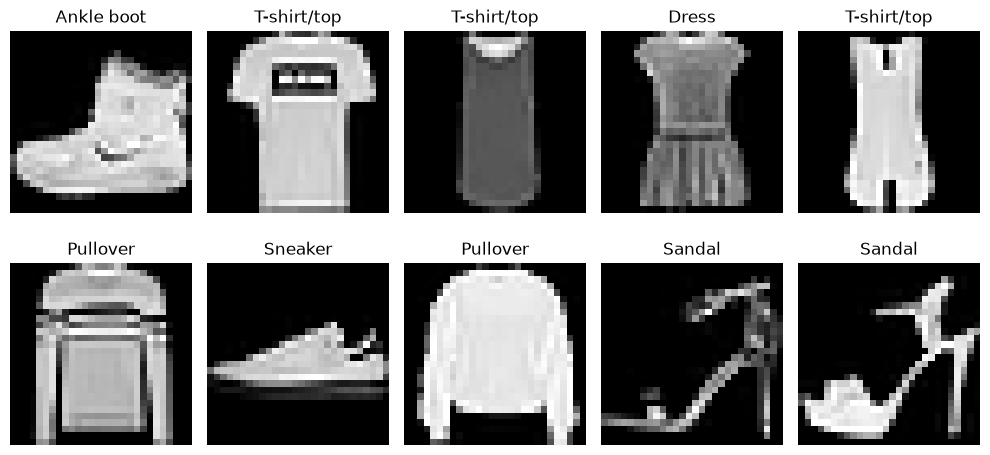

In [13]:

# Display sample clothing images

import matplotlib.pyplot as plt

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()



## 2. Data Preprocessing

Before training the models, I need to prepare the image data.

The original images contain pixel values between 0 and 255. I will normalise these values to a range of 0 to 1.

I will also prepare the images in two different shapes:
- Logistic Regression: Each image will be converted into 784 input features.
- CNN: Each image will retain its 28 × 28 structure with one colour channel.

This allows both models to use the same dataset while accepting the input format required by each model.


In [14]:

# Normalise image pixel values

X_train_norm = X_train / 255.0
X_test_norm = X_test / 255.0

print("Original pixel range:", X_train.min(), "to", X_train.max())
print("Normalised pixel range:", X_train_norm.min(), "to", X_train_norm.max())


Original pixel range: 0 to 255
Normalised pixel range: 0.0 to 1.0


In [15]:

# Flatten images for Logistic Regression

X_train_lr = X_train_norm.reshape(-1, 784)
X_test_lr = X_test_norm.reshape(-1, 784)

print("Logistic Regression training shape:", X_train_lr.shape)
print("Logistic Regression testing shape:", X_test_lr.shape)


Logistic Regression training shape: (60000, 784)
Logistic Regression testing shape: (10000, 784)


In [16]:

# Reshape images for CNN

X_train_cnn = X_train_norm.reshape(-1, 28, 28, 1)
X_test_cnn = X_test_norm.reshape(-1, 28, 28, 1)

print("CNN training shape:", X_train_cnn.shape)
print("CNN testing shape:", X_test_cnn.shape)


CNN training shape: (60000, 28, 28, 1)
CNN testing shape: (10000, 28, 28, 1)



## 3. Training and Validation Split

To evaluate the models fairly, I divided the original training dataset into training and validation sets.

I used an 80/20 split:
- 48,000 images for training
- 12,000 images for validation

The original 10,000 test images will remain separate until the final evaluation.

I used stratified splitting to maintain a similar proportion of each clothing category in both sets.

I also set random_state=42 so that the split can be reproduced.


In [17]:

# Split the original training data into training and validation

from sklearn.model_selection import train_test_split

X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_train_norm,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training images:", X_train_split.shape)
print("Validation images:", X_val.shape)
print("Testing images:", X_test_norm.shape)


Training images: (48000, 28, 28)
Validation images: (12000, 28, 28)
Testing images: (10000, 28, 28)


In [18]:

# Logistic Regression data

X_train_lr = X_train_split.reshape(-1, 784)
X_val_lr = X_val.reshape(-1, 784)

# CNN data

X_train_cnn = X_train_split.reshape(-1, 28, 28, 1)
X_val_cnn = X_val.reshape(-1, 28, 28, 1)

print("Logistic Regression:")
print("Train:", X_train_lr.shape)
print("Validation:", X_val_lr.shape)

print("\nCNN:")
print("Train:", X_train_cnn.shape)
print("Validation:", X_val_cnn.shape)


Logistic Regression:
Train: (48000, 784)
Validation: (12000, 784)

CNN:
Train: (48000, 28, 28, 1)
Validation: (12000, 28, 28, 1)



## 4. Model 1 — Logistic Regression (Classical ML)

I selected Logistic Regression as my classical Machine Learning model because it is relatively simple to implement and understand.

Although its name includes "Regression", it is commonly used for classification problems.

In this project, the model uses 784 pixel values from each image to predict one of the 10 clothing categories.

This model will provide a baseline to compare against the CNN.

I will train it using Scikit-learn and evaluate its performance on the validation dataset.


In [19]:

# Model 1: Logistic Regression

from sklearn.linear_model import LogisticRegression
import time

# Create the model
lr_model = LogisticRegression(
    max_iter=200,
    solver="lbfgs",
    C=1.0,
    random_state=42
)

# Measure training time
start_time = time.time()

# Train the model
lr_model.fit(X_train_lr, y_train_split)

lr_training_time = time.time() - start_time

print("Logistic Regression training completed")
print("Training time:", round(lr_training_time, 2), "seconds")


Logistic Regression training completed
Training time: 23.78 seconds


c:\venvs\fashion-ml\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [20]:

# Evaluate Logistic Regression on validation data

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score

# Predict clothing categories
lr_val_predictions = lr_model.predict(X_val_lr)

# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_val, lr_val_predictions)
lr_precision = precision_score(
    y_val, lr_val_predictions, average="macro", zero_division=0
)
lr_recall = recall_score(
    y_val, lr_val_predictions, average="macro", zero_division=0
)
lr_f1 = f1_score(
    y_val, lr_val_predictions, average="macro", zero_division=0
)

print("Logistic Regression - Validation Results")
print("Accuracy:", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall:", round(lr_recall, 4))
print("F1-score:", round(lr_f1, 4))


Logistic Regression - Validation Results
Accuracy: 0.8603
Precision: 0.8598
Recall: 0.8603
F1-score: 0.86


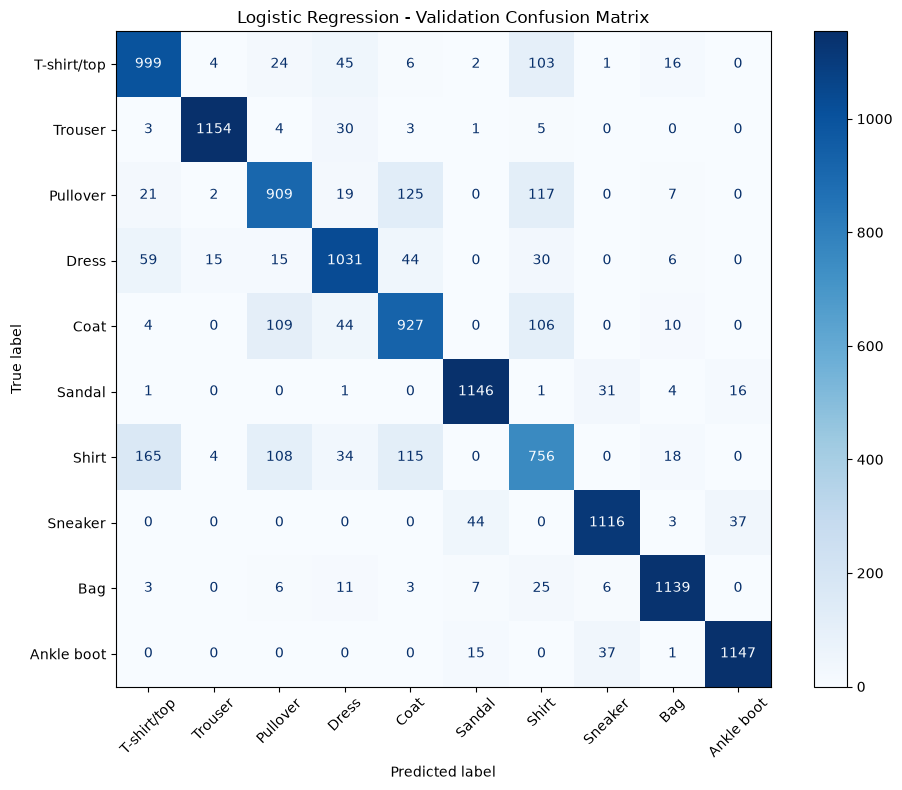

In [21]:

# Confusion matrix for Logistic Regression

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    lr_val_predictions,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Logistic Regression - Validation Confusion Matrix")
plt.gcf().set_size_inches(10, 8)
plt.tight_layout()
plt.show()


In [22]:
print("Validation accuracy:", round(lr_accuracy * 100, 2), "%")

Validation accuracy: 86.03 %



## 5. Model 2 — Convolutional Neural Network (CNN)

For my Deep Learning model, I selected a simple CNN.

Unlike Logistic Regression, which works with flattened pixel values, a CNN can learn spatial features such as edges, shapes and patterns.

I used two convolutional layers with max-pooling, followed by a dense layer and a final output layer containing 10 neurons.

The CNN uses the same training and validation images as Logistic Regression.


In [23]:

# Model 2: Convolutional Neural Network

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

tf.random.set_seed(42)

cnn_model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:

from tensorflow.keras.callbacks import EarlyStopping
import time

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

start_time = time.time()

history = cnn_model.fit(
    X_train_cnn,
    y_train_split,
    validation_data=(X_val_cnn, y_val),
    epochs=10,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

cnn_training_time = time.time() - start_time

print("CNN training completed")
print("Training time:", round(cnn_training_time, 2), "seconds")


Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.7750 - loss: 0.6201 - val_accuracy: 0.8428 - val_loss: 0.4391
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8587 - loss: 0.3974 - val_accuracy: 0.8633 - val_loss: 0.3761
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8763 - loss: 0.3458 - val_accuracy: 0.8799 - val_loss: 0.3382
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8855 - loss: 0.3143 - val_accuracy: 0.8866 - val_loss: 0.3148
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8953 - loss: 0.2884 - val_accuracy: 0.8945 - val_loss: 0.2958
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9021 - loss: 0.2682 - val_accuracy: 0.8978 - val_loss: 0.2831
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9089 - loss: 0.2508 - val_accuracy: 0.9015 - val_loss: 0.2740
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.9147 - loss: 0.2348 - val_acc

In [25]:

# CNN validation predictions

import numpy as np

cnn_val_probabilities = cnn_model.predict(X_val_cnn)
cnn_val_predictions = np.argmax(cnn_val_probabilities, axis=1)

cnn_accuracy = accuracy_score(y_val, cnn_val_predictions)
cnn_precision = precision_score(y_val, cnn_val_predictions, average="macro", zero_division=0)
cnn_recall = recall_score(y_val, cnn_val_predictions, average="macro", zero_division=0)
cnn_f1 = f1_score(y_val, cnn_val_predictions, average="macro", zero_division=0)

print("CNN - Validation Results")
print("Accuracy:", round(cnn_accuracy, 4))
print("Precision:", round(cnn_precision, 4))
print("Recall:", round(cnn_recall, 4))
print("F1-score:", round(cnn_f1, 4))


375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
CNN - Validation Results
Accuracy: 0.9048
Precision: 0.909
Recall: 0.9048
F1-score: 0.9061


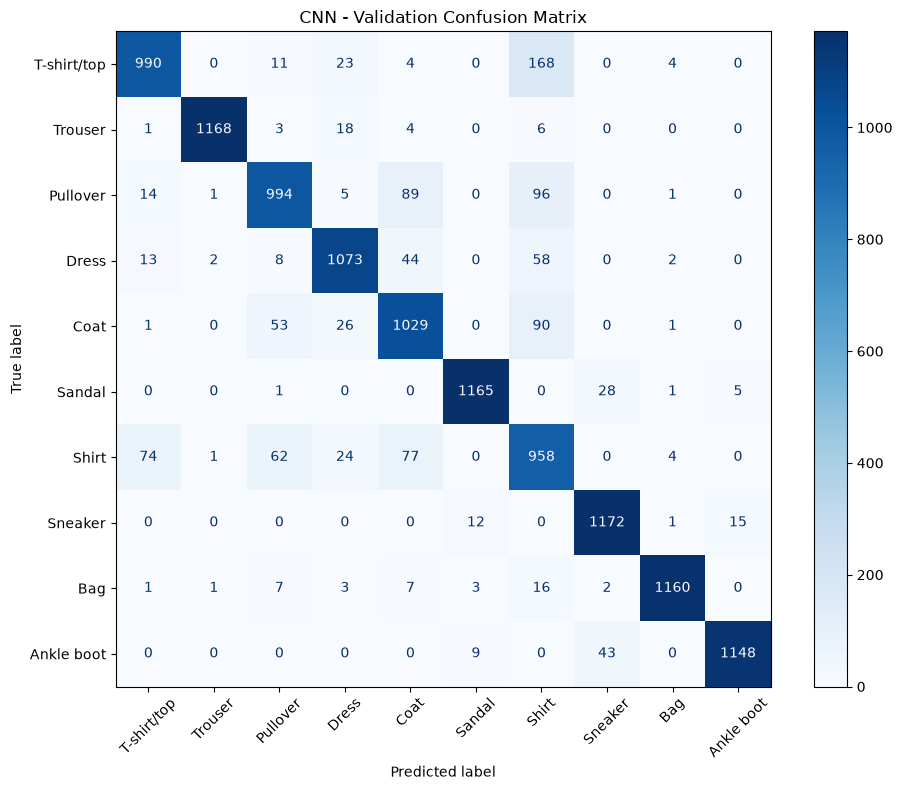

In [26]:

ConfusionMatrixDisplay.from_predictions(
    y_val,
    cnn_val_predictions,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("CNN - Validation Confusion Matrix")
plt.gcf().set_size_inches(10, 8)
plt.tight_layout()
plt.show()



## 6. Comparison of Classical ML and Deep Learning

Both models were evaluated using the same 12,000 validation images.

The CNN achieved better overall classification accuracy than Logistic Regression. However, I also want to compare precision, recall and F1-score, rather than relying only on accuracy.

The confusion matrices showed that the CNN improved classification of shirts, coats and pullovers. However, some confusion remains between visually similar clothing categories.


In [28]:

# Compare validation metrics

import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "CNN"],
    "Accuracy": [lr_accuracy, cnn_accuracy],
    "Precision": [lr_precision, cnn_precision],
    "Recall": [lr_recall, cnn_recall],
    "F1-score": [lr_f1, cnn_f1],
    "Training Time (s)": [lr_training_time, cnn_training_time]
})

display(comparison.round(4))



,Model,Accuracy,Precision,Recall,F1-score,Training Time (s)
0,Logistic Regression,0.8603,0.8598,0.8603,0.8600,23.7835
1,CNN,0.9048,0.9090,0.9048,0.9061,76.6610


In [29]:

# Save model comparison results

from pathlib import Path

output_folder = Path("../outputs/metrics")
output_folder.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    output_folder / "model_comparison.csv",
    index=False
)

print("Model comparison results saved successfully.")


Model comparison results saved successfully.



## 7. CNN Training and Validation Analysis

I examined the CNN training history to understand how its performance changed during training.

I compared training and validation accuracy, as well as training and validation loss.

This helps me identify whether the model is learning effectively or showing signs of overfitting.


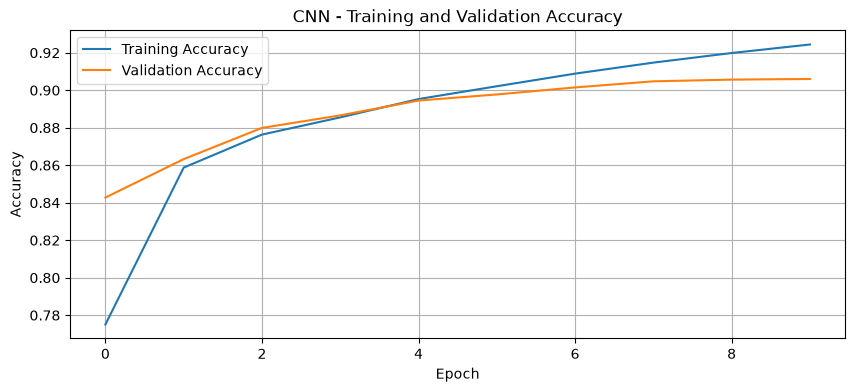

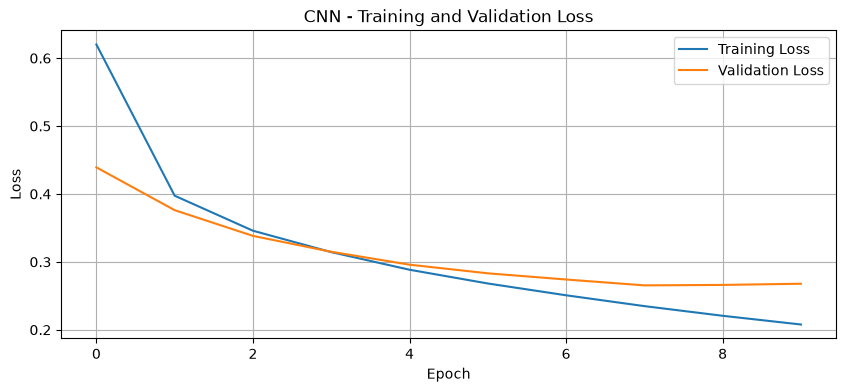

In [30]:

# Plot CNN accuracy and loss

plt.figure(figsize=(10, 4))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [31]:

# Save CNN learning curves

from pathlib import Path

figures_folder = Path("../outputs/figures")
figures_folder.mkdir(parents=True, exist_ok=True)

for metric in ["accuracy", "loss"]:

    plt.figure(figsize=(9, 5))

    plt.plot(history.history[metric], label="Training")
    plt.plot(history.history["val_" + metric], label="Validation")

    plt.title(f"CNN - Training and Validation {metric.title()}")
    plt.xlabel("Epoch")
    plt.ylabel(metric.title())
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        figures_folder / f"cnn_{metric}_curve.png",
        dpi=150
    )
    plt.close()

print("CNN learning curves saved successfully.")


CNN learning curves saved successfully.



## 8. Final Model Evaluation on Test Data

After training and validating both models, I evaluated them using the original 10,000 Fashion-MNIST test images.

These images were not used for training or selecting model settings.

I used accuracy, precision, recall and F1-score to compare the performance of Logistic Regression and CNN on unseen images.

This helps me understand whether the improvements observed during validation also appear on the test dataset.


In [32]:

# Logistic Regression - Test Evaluation

lr_test_predictions = lr_model.predict(X_test_lr)

lr_test_accuracy = accuracy_score(y_test, lr_test_predictions)
lr_test_precision = precision_score(y_test, lr_test_predictions, average="macro", zero_division=0)
lr_test_recall = recall_score(y_test, lr_test_predictions, average="macro", zero_division=0)
lr_test_f1 = f1_score(y_test, lr_test_predictions, average="macro", zero_division=0)

print("Logistic Regression - Test Results")
print("Accuracy:", round(lr_test_accuracy, 4))
print("Precision:", round(lr_test_precision, 4))
print("Recall:", round(lr_test_recall, 4))
print("F1-score:", round(lr_test_f1, 4))


Logistic Regression - Test Results
Accuracy: 0.8425
Precision: 0.8415
Recall: 0.8425
F1-score: 0.8418


In [33]:

# CNN - Test Evaluation

cnn_test_probabilities = cnn_model.predict(X_test_cnn)
cnn_test_predictions = np.argmax(cnn_test_probabilities, axis=1)

cnn_test_accuracy = accuracy_score(y_test, cnn_test_predictions)
cnn_test_precision = precision_score(y_test, cnn_test_predictions, average="macro", zero_division=0)
cnn_test_recall = recall_score(y_test, cnn_test_predictions, average="macro", zero_division=0)
cnn_test_f1 = f1_score(y_test, cnn_test_predictions, average="macro", zero_division=0)

print("CNN - Test Results")
print("Accuracy:", round(cnn_test_accuracy, 4))
print("Precision:", round(cnn_test_precision, 4))
print("Recall:", round(cnn_test_recall, 4))
print("F1-score:", round(cnn_test_f1, 4))


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
CNN - Test Results
Accuracy: 0.8977
Precision: 0.9023
Recall: 0.8977
F1-score: 0.8991


In [34]:

# Final test comparison

test_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "CNN"],
    "Accuracy": [lr_test_accuracy, cnn_test_accuracy],
    "Precision": [lr_test_precision, cnn_test_precision],
    "Recall": [lr_test_recall, cnn_test_recall],
    "F1-score": [lr_test_f1, cnn_test_f1]
})

display(test_comparison.round(4))

test_comparison.to_csv(
    output_folder / "test_model_comparison.csv",
    index=False
)

print("Final test comparison saved successfully.")


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.8425,0.8415,0.8425,0.8418
1,CNN,0.8977,0.9023,0.8977,0.8991


Final test comparison saved successfully.



## 9. Explainable AI — Grad-CAM

Although the CNN achieved higher classification accuracy, I also wanted to understand which parts of an image influenced its predictions.

I selected Grad-CAM because it can highlight image regions that contribute to a CNN's predicted class.

I will examine a small number of test images and compare the highlighted regions with the actual and predicted clothing categories.

Grad-CAM provides an approximate visual explanation, rather than proving exactly how the model makes every decision.


In [35]:

# Prepare CNN for Grad-CAM

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Locate the last convolutional layer
last_conv_layer = [
    layer for layer in cnn_model.layers
    if isinstance(layer, tf.keras.layers.Conv2D)
][-1]

print("Last convolutional layer:", last_conv_layer.name)


Last convolutional layer: conv2d_1


In [39]:


# Grad-CAM function compatible with Keras 3

def make_gradcam_heatmap(image, model, conv_layer):

    # Create a new input for the trained CNN
    inputs = tf.keras.Input(shape=(28, 28, 1))

    x = inputs
    conv_output = None

    # Pass the input through the existing trained layers
    for layer in model.layers:
        x = layer(x)

        if layer is conv_layer:
            conv_output = x

    # Return both convolution features and predictions
    grad_model = tf.keras.Model(
        inputs=inputs,
        outputs=[conv_output, x]
    )

    # Calculate the gradients for the predicted class
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image)

        class_index = tf.argmax(predictions[0])
        class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, conv_outputs)

    # Average gradients to obtain feature importance weights
    weights = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    # Create Grad-CAM heatmap
    heatmap = tf.reduce_sum(
        conv_outputs[0] * weights,
        axis=-1
    )

    # Keep positive contributions
    heatmap = tf.maximum(heatmap, 0)

    # Normalise between 0 and 1
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()



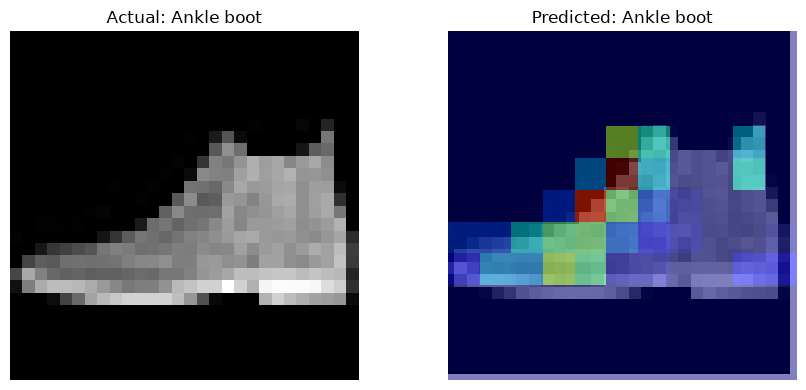

In [41]:

# Explain one CNN prediction

image_index = 0

image = X_test_cnn[image_index:image_index + 1]

heatmap = make_gradcam_heatmap(
    image,
    cnn_model,
    last_conv_layer
)

predicted_class = cnn_test_predictions[image_index]
actual_class = y_test[image_index]

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(X_test[image_index], cmap="gray")
plt.title(f"Actual: {class_names[actual_class]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(X_test[image_index], cmap="gray")
plt.imshow(
    heatmap,
    cmap="jet",
    alpha=0.5,
    extent=(0, 28, 28, 0)
)
plt.title(f"Predicted: {class_names[predicted_class]}")
plt.axis("off")

plt.tight_layout()
plt.show()


In [43]:
plt.tight_layout()

plt.savefig(
    figures_folder / "cnn_gradcam_example.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>


### Grad-CAM Observation

For the first test image, the CNN correctly predicted the category as Ankle boot.

The Grad-CAM heatmap highlighted regions around the footwear, particularly the upper and middle parts of the image.

This suggests that these image regions contributed to the model's prediction.

However, Grad-CAM does not explain every part of the model's decision, so the result should be interpreted carefully.


In [44]:

# Find an incorrectly classified test image

wrong_indices = np.where(
    cnn_test_predictions != y_test
)[0]

wrong_index = wrong_indices[0]

print("Image index:", wrong_index)
print("Actual:", class_names[y_test[wrong_index]])
print("Predicted:", class_names[cnn_test_predictions[wrong_index]])


Image index: 17
Actual: Coat
Predicted: Shirt


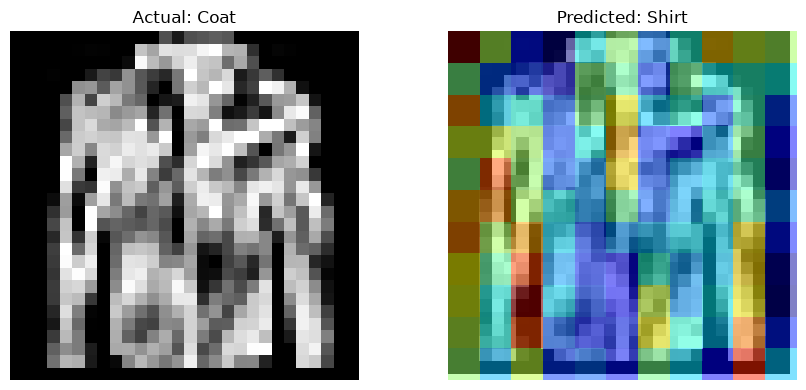

In [45]:

# Grad-CAM for an incorrect prediction

image = X_test_cnn[wrong_index:wrong_index + 1]

heatmap = make_gradcam_heatmap(
    image,
    cnn_model,
    last_conv_layer
)

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(X_test[wrong_index], cmap="gray")
plt.title(f"Actual: {class_names[y_test[wrong_index]]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(X_test[wrong_index], cmap="gray")
plt.imshow(
    heatmap,
    cmap="jet",
    alpha=0.5,
    extent=(0, 28, 28, 0)
)
plt.title(
    f"Predicted: {class_names[cnn_test_predictions[wrong_index]]}"
)
plt.axis("off")

plt.tight_layout()

plt.savefig(
    figures_folder / "cnn_gradcam_incorrect.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()



### Grad-CAM Findings and Reflection

I examined two test images using Grad-CAM.

In the first example, the CNN correctly classified an ankle boot. The heatmap highlighted areas around the footwear, suggesting that these regions contributed to the prediction.

In the second example, the CNN incorrectly classified a coat as a shirt. The heatmap highlighted different parts of the garment, but it did not clearly explain why the model selected the wrong category.

This helped me understand that explainability techniques can provide useful visual information, but they do not guarantee that a model's prediction is correct or fully explainable.



## 10. Bias and Diagnostic Analysis

I investigated whether the CNN performed equally well across all ten clothing categories.

Fashion-MNIST does not provide demographic information, so I could not evaluate fairness across groups of people.

Instead, I compared recall for each clothing category to identify differences in classification performance.

These differences can reveal potential limitations in the dataset or model, particularly for visually similar items.


In [46]:

# Calculate recall for each clothing category

from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    cnn_test_predictions,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

category_results = pd.DataFrame(report).T

category_recall = category_results.loc[
    class_names, ["precision", "recall", "f1-score"]
]

display(category_recall.round(3))


,precision,recall,f1-score
T-shirt/top,0.887,0.804,0.844
Trouser,0.998,0.968,0.983
Pullover,0.871,0.822,0.846
Dress,0.908,0.887,0.897
Coat,0.818,0.870,0.843
Sandal,0.988,0.967,0.977
Shirt,0.659,0.758,0.705
Sneaker,0.928,0.986,0.956
Bag,0.982,0.966,0.974
Ankle boot,0.984,0.949,0.966


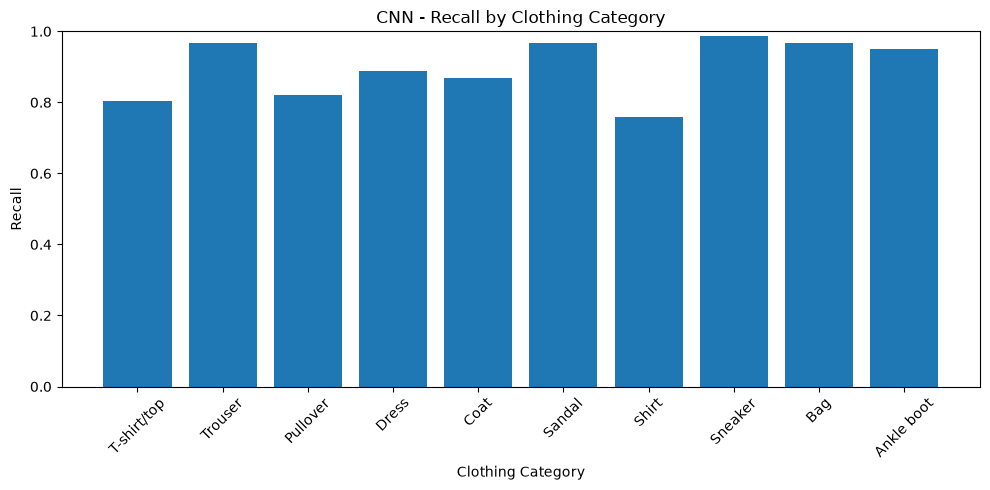

In [47]:

# Plot recall for each clothing category

plt.figure(figsize=(10, 5))

plt.bar(
    category_recall.index,
    category_recall["recall"]
)

plt.title("CNN - Recall by Clothing Category")
plt.xlabel("Clothing Category")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    figures_folder / "cnn_category_recall.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [48]:

# Save category performance results

category_recall.to_csv(
    output_folder / "cnn_category_performance.csv"
)

print("Category performance results saved successfully.")


Category performance results saved successfully.



### Category-Level Diagnostic Findings

The results showed that CNN performance was not equal across all clothing categories.

Sneakers, trousers and sandals achieved relatively high recall, while shirts had the lowest recall.

I also observed similar difficulties in the Logistic Regression confusion matrix, particularly for visually similar clothing categories.

This suggests that classifying upper-body clothing is more challenging than distinguishing certain footwear categories in this dataset.

For a real online clothing retailer, these differences could lead to more frequent incorrect categorisation of some products.

However, this analysis measures differences between clothing categories, not fairness across demographic groups.



## 11. Ethical Considerations

### Data Privacy

Fashion-MNIST contains small grayscale clothing images and category labels rather than identifiable customer information.

However, if a similar model were deployed by an online retailer, the company would need to consider where product images come from, whether it has permission to use them, and how any related personal information is protected.

### Algorithmic Fairness and Bias

My category-level analysis showed that the CNN performed differently across clothing categories.

For example, shirts had lower recall than footwear categories. This could mean that some types of products are more likely to be placed into incorrect categories.

Fashion-MNIST does not contain demographic attributes, so I cannot use this dataset to determine whether the model behaves fairly across different groups of people.

### Consequences of Incorrect Predictions

In an online retail setting, a false prediction could place a coat into the shirt category.

This might make the product harder for customers to find and could affect product visibility or sales.

Although the consequences are less serious than in healthcare or other high-risk applications, repeated errors could still affect customers and sellers.

### Responsible Use

I would recommend using the model to support automatic product categorisation rather than relying on it completely.

Low-confidence predictions could be reviewed by a person before the product category is confirmed.

The model should also be monitored to identify categories with consistently high error rates.



## 12. Deployment Considerations

Based on the test results, I would select the CNN for a small pilot of automatic clothing categorisation because it achieved better overall performance than Logistic Regression.

A possible application would be an online retail system where a seller uploads a clothing image and the model suggests a product category.

The CNN could be made available through an API using a framework such as FastAPI. A cloud platform could host the model if the number of requests increased.

Before deployment, the system would need to check image quality, handle uncertain predictions, and monitor classification errors.

The original Fashion-MNIST images are small, grayscale and relatively simple. Real product photographs may contain different backgrounds, colours, angles and lighting conditions.

Therefore, the model should be tested on representative real-world product images before being used in a live retail system.

I would also monitor accuracy by clothing category and retrain the model when sufficient new labelled data becomes available.
